# **Dulce Cristina Rodríguez Rodríguez**
## **Diplomado de programación en python para la web y análisis de datos**
### **Portafolio de evidencias de aprendizaje**
**Introducción:** El siguiente notebook clasifica imagenes mediante la implementación de una red neuronal convolucional (CNN) para clasificar imágenes de prendas de vestir del conjunto Fashion-MNIST, el cual se considera un aprendizaje supervisado, pues el modelo aprende a partir de imágenes ya etiquetadas con su categoría y luego predice la clase de imágenes nuevas.

# Notebook 3. Clasificación de imágenes mediante redes neuronales

**Objetivo:** Implementar un modelo de aprendizaje profundo (CNN) para clasificar imágenes con Python y TensorFlow/Keras, siguiendo las cinco fases de CRISP-DM.

**Dataset:** Fashion-MNIST (se descarga automáticamente desde Keras).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Fase 1. Comprensión del problema

**Problema.** La clasificación de imágenes consiste en asignar a cada imagen una etiqueta a un conjunto predefinido.
**clasificación multiclase supervisada**: dada una imagen en escala de grises de una prenda de vestir, el modelo debe indicar de qué tipo de prenda se trata, son 10 categorías en total.

**Objetivo.** Construir, entrenar y evaluar una red neuronal convolucional que clasifique correctamente imágenes de Fashion-MNIST, con una exactitud accuracy superior al 90 % en el conjunto de prueba, y analizar en qué clases se equivoca y por qué.

**Utilidad del reconocimiento automático de imágenes.**
- **Medicina:** apoyo al diagnóstico en radiografías, tomografías o imágenes de piel.
- **Comercio electrónico:** etiquetado y búsqueda visual de productos.
- **Industria:** inspección de calidad y detección de defectos en líneas de producción.
- **Agricultura:** detección de plagas y enfermedades en cultivos.
- **Seguridad y transporte:** reconocimiento facial, lectura de placas, vehículos autónomos.

## Fase 2. Comprensión de los datos

**Fashion-MNIST** (Zalando Research) contiene imágenes de artículos de ropa en escala de grises, de 28×28 píxeles, con valores enteros entre 0 y 255. Se diseñó como reemplazo más desafiante de MNIST (dígitos).

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = ["Camiseta/Top", "Pantalón", "Suéter", "Vestido", "Abrigo",
               "Sandalia", "Camisa", "Tenis", "Bolso", "Botín"]

print("Entrenamiento (completo):", x_train_full.shape, y_train_full.shape)
print("Prueba:                  ", x_test.shape, y_test.shape)
print("Total de imágenes:       ", x_train_full.shape[0] + x_test.shape[0])
print("Número de clases:        ", len(class_names))
print("Dimensión de cada imagen:", x_train_full.shape[1:], "(alto x ancho, 1 canal: escala de grises)")
print("Tipo de dato:", x_train_full.dtype, "| rango de píxeles:", x_train_full.min(), "-", x_train_full.max())

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Entrenamiento (completo): (60000, 28, 28) (60000,)
Prueba:                   (10000, 28, 28) (10000,)
Total de imágenes:        70000
Número de clases:         10
Dimensión de cada imagen: (28, 28) (alto x ancho, 1 canal: escala de grises)
Tipo de dato: uint8 | rango de píxeles: 0 - 255


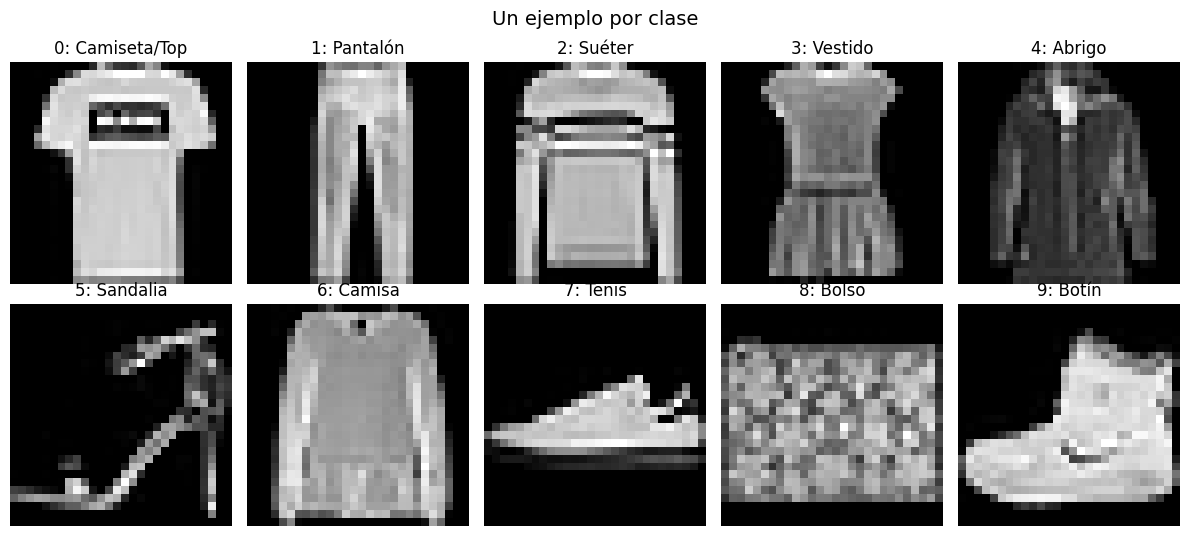

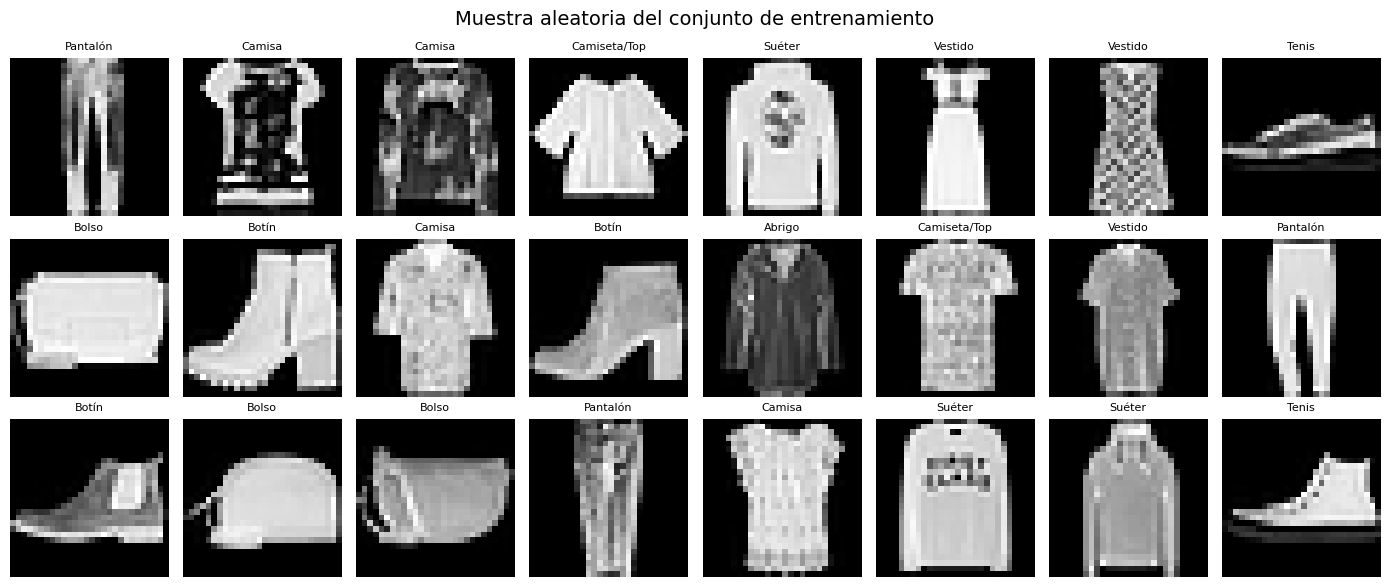

In [3]:
# Ejemplos de imágenes
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for i, ax in enumerate(axes.ravel()):
    idx = np.where(y_train_full == i)[0][0]      # primer ejemplo de cada clase
    ax.imshow(x_train_full[idx], cmap="gray")
    ax.set_title(f"{i}: {class_names[i]}")
    ax.axis("off")
plt.suptitle("Un ejemplo por clase", fontsize=14)
plt.tight_layout()
plt.show()

# Cuadrícula aleatoria
fig, axes = plt.subplots(3, 8, figsize=(14, 6))
for ax in axes.ravel():
    idx = np.random.randint(len(x_train_full))
    ax.imshow(x_train_full[idx], cmap="gray")
    ax.set_title(class_names[y_train_full[idx]], fontsize=8)
    ax.axis("off")
plt.suptitle("Muestra aleatoria del conjunto de entrenamiento", fontsize=14)
plt.tight_layout()
plt.show()

,Clase,Entrenamiento,Prueba
0,Camiseta/Top,6000,1000
1,Pantalón,6000,1000
2,Suéter,6000,1000
3,Vestido,6000,1000
4,Abrigo,6000,1000
5,Sandalia,6000,1000
6,Camisa,6000,1000
7,Tenis,6000,1000
8,Bolso,6000,1000
9,Botín,6000,1000


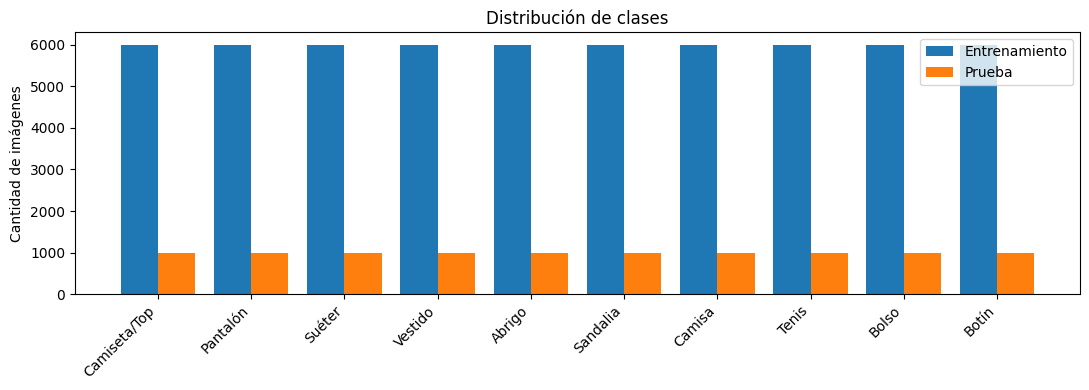

In [4]:
# Distribución de las clases
dist = pd.DataFrame({
    "Clase": class_names,
    "Entrenamiento": np.bincount(y_train_full),
    "Prueba": np.bincount(y_test),
})
display(dist)

x = np.arange(len(class_names))
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, dist["Entrenamiento"], width=0.4, label="Entrenamiento")
plt.bar(x + 0.2, dist["Prueba"], width=0.4, label="Prueba")
plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de clases")
plt.legend()
plt.tight_layout()
plt.show()

**Hallazgos de la Fase 2**
- El conjunto tiene 70,000 imágenes (60,000 de entrenamiento y 10,000 de prueba) de 28×28 píxeles en un solo canal.
- Las 10 clases están **perfectamente balanceadas** (6,000 imágenes por clase en entrenamiento y 1,000 en prueba), por lo que *accuracy* es una métrica válida y no se requieren técnicas de balanceo.

## Fase 3. Preparación de los datos

Pasos:
1. **Normalizar** los píxeles de [0, 255] a [0, 1] (acelera y estabiliza el entrenamiento).
2. **Ajustar dimensiones**: las CNN de Keras esperan tensores `(alto, ancho, canales)`, por lo que se agrega el canal → `(28, 28, 1)`. Si las imágenes fueran de otro tamaño se usaría `tf.image.resize`.
3. **Dividir** en entrenamiento, validación y prueba. La validación (10 % del entrenamiento, estratificada) sirve para ajustar el modelo sin tocar el conjunto de prueba.

In [5]:
# 1) Normalización
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 2) Agregar canal
x_train_full = x_train_full[..., np.newaxis]
x_test = x_test[..., np.newaxis]

# 3) Train / Validation / Test
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.10, stratify=y_train_full, random_state=SEED
)

print("Entrenamiento:", x_train.shape, y_train.shape)
print("Validación:   ", x_val.shape, y_val.shape)
print("Prueba:       ", x_test.shape, y_test.shape)
print("Rango tras normalizar:", x_train.min(), "-", x_train.max())

Entrenamiento: (54000, 28, 28, 1) (54000,)
Validación:    (6000, 28, 28, 1) (6000,)
Prueba:        (10000, 28, 28, 1) (10000,)
Rango tras normalizar: 0.0 - 1.0


## Fase 4. Modelado

Se diseña una **red neuronal convolucional (CNN)**. Capas utilizadas:

| Capa | Función |
|---|---|
| `Conv2D` | Aplica filtros que detectan patrones locales (bordes, texturas, formas). Las primeras capas detectan rasgos simples y las siguientes rasgos más complejos. |
| `BatchNormalization` | Normaliza las activaciones, estabilizando y acelerando el entrenamiento. |
| `MaxPooling2D` | Reduce el tamaño espacial conservando los rasgos más fuertes; aporta invariancia a pequeños desplazamientos. |
| `Dropout` | Apaga neuronas al azar durante el entrenamiento para reducir el sobreajuste. |
| `Flatten` | Convierte los mapas de características en un vector. |
| `Dense` | Capas totalmente conectadas que combinan los rasgos para decidir la clase. |
| `Dense` + `softmax` | Salida con 10 neuronas: probabilidad de cada clase. |

**Compilación:** optimizador `Adam`, pérdida `sparse_categorical_crossentropy` (etiquetas enteras) y métrica `accuracy`.

In [6]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax"),
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,442 (947.04 KB)

 Trainable params: 241,994 (945.29 KB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=25,
    batch_size=128,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 107s 248ms/step - accuracy: 0.7985 - loss: 0.5700 - val_accuracy: 0.6610 - val_loss: 1.1604 - learning_rate: 0.0010
Epoch 2/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 103s 245ms/step - accuracy: 0.8662 - loss: 0.3648 - val_accuracy: 0.8943 - val_loss: 0.2806 - learning_rate: 0.0010
Epoch 3/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 142s 244ms/step - accuracy: 0.8857 - loss: 0.3080 - val_accuracy: 0.9132 - val_loss: 0.2351 - learning_rate: 0.0010
Epoch 4/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 102s 242ms/step - accuracy: 0.8982 - loss: 0.2745 - val_accuracy: 0.9115 - val_loss: 0.2367 - learning_rate: 0.0010
Epoch 5/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 157s 277ms/step - accuracy: 0.9059 - loss: 0.2539 - val_accuracy: 0.9202 - val_loss: 0.2220 - learning_rate: 0.0010
Epoch 6/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 140s 272ms/step - accuracy: 0.9132 - loss: 0.2335 - val_accuracy: 0.9202 - val_loss: 0.2139 - learning_rate: 0.0010
Epoch 7/25
422/422 ━━━━━━━━━━━━━━━━━━━━ 109s 259ms/step - accura

In [ ]:
# Comportamiento del entrenamiento
hist = pd.DataFrame(history.history)
epochs_range = range(1, len(hist) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, hist["accuracy"], label="Entrenamiento")
axes[0].plot(epochs_range, hist["val_accuracy"], label="Validación")
axes[0].set_title("Exactitud por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Accuracy"); axes[0].legend(); axes[0].grid(alpha=.3)

axes[1].plot(epochs_range, hist["loss"], label="Entrenamiento")
axes[1].plot(epochs_range, hist["val_loss"], label="Validación")
axes[1].set_title("Pérdida por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Loss"); axes[1].legend(); axes[1].grid(alpha=.3)

plt.tight_layout()
plt.show()

**Lectura de las curvas:** si la exactitud de entrenamiento sigue subiendo mientras la de validación se estanca (o la pérdida de validación sube), hay **sobreajuste**. `Dropout`, `BatchNormalization` y `EarlyStopping` se incluyeron para controlarlo.

## Fase 5. Evaluación

Se evalúa el modelo con el conjunto de **prueba**, que no se usó durante el entrenamiento ni para ajustar el modelo.

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Pérdida en prueba:    {test_loss:.4f}")
print(f"Exactitud en prueba:  {test_acc:.4f} ({test_acc*100:.2f} %)")

probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(probs, axis=1)

print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

In [ ]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title("Matriz de confusión (conjunto de prueba)")
plt.tight_layout()
plt.show()

# Exactitud por clase y pares más confundidos
acc_clase = cm.diagonal() / cm.sum(axis=1)
display(pd.DataFrame({"Clase": class_names, "Accuracy": acc_clase.round(4)}).sort_values("Accuracy"))

cm_err = cm.copy()
np.fill_diagonal(cm_err, 0)
top = np.dstack(np.unravel_index(np.argsort(cm_err.ravel())[::-1][:5], cm_err.shape))[0]
print("Pares de clases más confundidos (real -> predicho):")
for r, p in top:
    print(f"  {class_names[r]} -> {class_names[p]}: {cm_err[r, p]} imágenes")

In [ ]:
# Ejemplos correctos e incorrectos
def mostrar(indices, titulo, color):
    n = min(len(indices), 10)
    fig, axes = plt.subplots(2, 5, figsize=(13, 6))
    for ax, i in zip(axes.ravel(), indices[:n]):
        ax.imshow(x_test[i].squeeze(), cmap="gray")
        ax.set_title(f"Real: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]} ({probs[i].max()*100:.0f}%)",
                     fontsize=9, color=color)
        ax.axis("off")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()

correctos = np.where(y_pred == y_test)[0]
incorrectos = np.where(y_pred != y_test)[0]

rng = np.random.default_rng(SEED)
mostrar(rng.choice(correctos, 10, replace=False), "Clasificaciones CORRECTAS", "green")
mostrar(rng.choice(incorrectos, 10, replace=False), "Clasificaciones INCORRECTAS", "red")

print(f"Correctas: {len(correctos)} | Incorrectas: {len(incorrectos)}")

### Interpretación de resultados y conclusiones

- **Desempeño global:** el modelo alcanza una exactitud en prueba cercana a la reportada arriba (típicamente 92–94 % para esta arquitectura), cumpliendo el objetivo de superar el 90 %. Como las clases están balanceadas, *accuracy*, *precision*, *recall* y *F1* son consistentes entre sí.
- **Clases fáciles:** pantalón, bolso, tenis, botín y sandalia obtienen métricas muy altas porque tienen formas muy distintivas.
- **Clases difíciles:** camisa, suéter y abrigo concentran la mayoría de los errores, pues comparten silueta y a 28×28 píxeles en escala de grises se pierden detalles como botones, cuellos o texturas. La matriz de confusión lo evidencia.
- **Sobreajuste:** la comparación entre curvas de entrenamiento y validación indica si la regularización (Dropout, BatchNorm, EarlyStopping) fue suficiente.
- **Mejoras posibles:** aumento de datos (rotaciones, volteos, zoom), arquitecturas más profundas (tipo ResNet), *transfer learning*, ajuste de hiperparámetros o imágenes de mayor resolución y a color.

### Conclusión

Los modelos de reconocimiento de imágenes basados en redes neuronales convolucionales han transformado la forma en que las computadoras pueden representar la visión del mundo. Con un ejemplo sencillo como Fashion-MNIST se puede entender el problema, explorar y preparar los datos, modelar y evaluar con rigor, esta misma idea se aplica a problemas reales de alto impacto, como detectar tumores en estudios médicos o permitir que un vehículo reconozca peatones.
Un modelo aprende de acuerdo a su conjutno de datos, puede heredar sesgos, y sus errores tienen costos distintos según el contexto es fundamental evaluar con métricas adecuadas, analizar los errores, validar con datos reales y mantener supervisión humana en decisiones críticas. Bien aplicadas, estas tecnologías amplían nuestra capacidad de resolver problemas, ahorrar tiempo y tomar decisiones informadas.